# 04 · Logistic Regression and class weights
The first real model. Tests Logistic Regression with and without class weights using 5-fold stratified cross-validation (CV) on the training set, then compares the two at equal review workload. Outputs are risk scores used for ranking, not calibrated probabilities.

## 1. Import the modelling tools
**What it does:** imports the pipeline, preprocessing, Logistic Regression, cross-validation and metric tools used in this notebook.

**Why:** keeps all scikit-learn imports in one place.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, f1_score

## 2. Load the training data
**What it does:** loads `train.csv`, separates the 92 financial ratios (`X_train`) from the `Bankrupt?` target (`y_train`) and sets readable number formatting.

**Why:** only the training set is used; the test set stays untouched until notebook 06.

In [14]:
import pandas as pd
import numpy as np
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.4g}".format)

train = pd.read_csv("data/train.csv")
X_train = train.drop(columns="Bankrupt?")
y_train = train["Bankrupt?"]
print(X_train.shape, "| bankrupt:", y_train.sum())

(5455, 92) | bankrupt: 176


## 3. Count the columns with values above 1
**What it does:** counts the columns in the training data that contain at least one value above 1.

**Why:** the full dataset has 24 such columns, but the training data shows 23: the only large `Current Ratio` value fell into the test set. This is why `log1p` is applied to all columns instead of a list built from the training data.

In [15]:
large_cols = [c for c in X_train.columns if (X_train[c] > 1).any()]
print("Columns with values above 1 (training data):", len(large_cols))

Columns with values above 1 (training data): 23


## 4. What `log1p` does to a column
**What it does:** shows the minimum, quartiles and maximum of two columns before and after `log1p` (log(1 + x)): one with very large values (`Cash Turnover Rate`) and one fully inside 0–1 (`Debt ratio %`). The data itself is not changed.

**Why:** Logistic Regression needs columns on comparable scales. `log1p` turns 10 billion into about 23, keeps the order of values, and barely changes values between 0 and 1.

In [16]:
for col in ["Cash Turnover Rate", "Debt ratio %"]:
    example = pd.DataFrame({"original": X_train[col], "after log1p": np.log1p(X_train[col])})
    print(f"\n{col}")
    print(example.describe().loc[["min", "25%", "50%", "75%", "max"]])


Cash Turnover Rate
     original  after log1p
min         0            0
25% 0.0002755    0.0002755
50%  1.14e+09        20.85
75%  4.55e+09        22.24
max     1e+10        23.03

Debt ratio %
     original  after log1p
min         0            0
25%   0.07286      0.07033
50%    0.1114       0.1056
75%    0.1489       0.1388
max         1       0.6931


## 5. Define the folds and the metrics
**What it does:** creates the same 5 stratified folds (seed 42) and the same metrics as notebook 03: accuracy, precision, recall, F1, ROC-AUC and PR-AUC (`average_precision`).

**Why:** identical folds and metrics make the results directly comparable with the baseline.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy":  "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall":    "recall",
    "f1":        make_scorer(f1_score, zero_division=0),
    "roc_auc":   "roc_auc",
    "pr_auc":    "average_precision",
}

## 6. Build the two Logistic Regression pipelines
**What it does:** defines a pipeline of three steps (`log1p`, then standardisation, then Logistic Regression) in two versions: without class weights and with `class_weight="balanced"`, which makes a missed bankruptcy cost about 30 times more than a misclassified healthy record.

**Why:** a pipeline refits the scaling inside each training fold, so the scored fold never influences preprocessing (no leakage). Comparing the two versions shows what class weighting actually changes.

In [18]:
def make_lr_pipeline(class_weight=None):
    return Pipeline([
        ("log",   FunctionTransformer(np.log1p)),          # step 1: pull in huge values
        ("scale", StandardScaler()),                       # step 2: put columns on the same scale
        ("model", LogisticRegression(class_weight=class_weight,
                                     max_iter=5000,
                                     random_state=42)),     # step 3: the model
    ])

models = {
    "LogReg (no weights)":       make_lr_pipeline(class_weight=None),
    "LogReg (balanced weights)": make_lr_pipeline(class_weight="balanced"),
}

## 7. Cross-validate both models
**What it does:** runs 5-fold cross-validation (CV) on each pipeline and shows the average of each metric and its standard deviation across the folds.

**Why:** the averages show how each model performs; the standard deviations show how much results move between folds, so small differences are not over-read.

In [19]:
results, spread = {}, {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {m: scores[f"test_{m}"].mean() for m in scoring}
    spread[name]  = {m: scores[f"test_{m}"].std()  for m in scoring}

print("Average over the 5 folds:")
display(pd.DataFrame(results).T.round(3))
print("How much the score varies between folds (standard deviation):")
display(pd.DataFrame(spread).T.round(3))

Average over the 5 folds:


,accuracy,precision,recall,f1,roc_auc,pr_auc
LogReg (no weights),0.968,0.488,0.222,0.302,0.912,0.38
LogReg (balanced weights),0.871,0.168,0.75,0.274,0.888,0.337


How much the score varies between folds (standard deviation):


,accuracy,precision,recall,f1,roc_auc,pr_auc
LogReg (no weights),0.002,0.067,0.067,0.074,0.022,0.043
LogReg (balanced weights),0.011,0.018,0.08,0.027,0.04,0.047


## 8. Confusion matrices
**What it does:** gives every training record one out-of-fold prediction at the default 0.5 threshold and counts the records flagged, bankruptcies caught, false alarms and bankruptcies missed.

**Why:** translates the percentages into numbers of records an analyst would actually review.

In [20]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

for name, model in models.items():
    y_pred = cross_val_predict(model, X_train, y_train, cv=cv)
    cm = confusion_matrix(y_train, y_pred)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n{name}")
    print(pd.DataFrame(cm, index=["Actual: healthy", "Actual: bankrupt"],
                           columns=["Predicted: healthy", "Predicted: bankrupt"]))
    print(f"Flagged as bankrupt: {tp + fp} companies")
    print(f"  - real bankruptcies caught (TP): {tp}")
    print(f"  - false alarms (FP):             {fp}")
    print(f"Bankruptcies missed (FN):          {fn}")


LogReg (no weights)
                  Predicted: healthy  Predicted: bankrupt
Actual: healthy                 5239                   40
Actual: bankrupt                 137                   39
Flagged as bankrupt: 79 companies
  - real bankruptcies caught (TP): 39
  - false alarms (FP):             40
Bankruptcies missed (FN):          137

LogReg (balanced weights)
                  Predicted: healthy  Predicted: bankrupt
Actual: healthy                 4621                  658
Actual: bankrupt                  44                  132
Flagged as bankrupt: 790 companies
  - real bankruptcies caught (TP): 132
  - false alarms (FP):             658
Bankruptcies missed (FN):          44


## 9. Out-of-fold risk scores
**What it does:** asks each model for a risk score (`predict_proba`) instead of a yes/no answer, using cross-validation so every record is scored by a model that never saw it, then compares the median score of healthy and bankrupt records.

**Why:** risk scores are what an analyst would rank by. They are not calibrated probabilities: with balanced weights, the scores are pushed upward.

In [21]:
risk_scores = {}
for name, model in models.items():
    risk_scores[name] = cross_val_predict(model, X_train, y_train, cv=cv,
                                          method="predict_proba")[:, 1]

scores_df = pd.DataFrame(risk_scores)
scores_df["Bankrupt?"] = y_train.values
print("Median risk score by actual outcome:")
scores_df.groupby("Bankrupt?").median().round(3)

Median risk score by actual outcome:


,LogReg (no weights),LogReg (balanced weights)
Bankrupt?,,
0,0.003,0.029
1,0.196,0.884


## 10. Review-capacity table
**What it does:** ranks records by risk score and counts the bankruptcies found if analysts review exactly the top 5%, 10%, 15% or 20%, with the recall, precision and score threshold each capacity implies.

**Why:** compares models on the business question (bankruptcies found for a given workload) instead of at an arbitrary 0.5 threshold.

In [22]:
def capacity_table(scores, y_true, capacities=(0.05, 0.10, 0.15, 0.20)):
    y_true = np.asarray(y_true)
    order = np.argsort(-scores)                  # company positions, riskiest first
    rows = []
    for cap in capacities:
        k = int(round(cap * len(scores)))        # how many companies analysts review
        flagged = order[:k]                      # the top-k riskiest companies
        caught = int(y_true[flagged].sum())      # real bankruptcies among them
        rows.append({
            "capacity": f"{int(cap * 100)}%",
            "companies_reviewed": k,
            "bankruptcies_caught": caught,
            "recall": round(caught / y_true.sum(), 3),
            "precision": round(caught / k, 3),
            "score_threshold": round(float(scores[order[k - 1]]), 4),
        })
    return pd.DataFrame(rows)

for name in models:
    print(f"\n{name}")
    print(capacity_table(risk_scores[name], y_train).to_string(index=False))


LogReg (no weights)
capacity  companies_reviewed  bankruptcies_caught  recall  precision  score_threshold
      5%                 273                   99   0.562      0.363           0.1612
     10%                 546                  124   0.705      0.227           0.0653
     15%                 818                  138   0.784      0.169           0.0379
     20%                1091                  156   0.886      0.143           0.0229

LogReg (balanced weights)
capacity  companies_reviewed  bankruptcies_caught  recall  precision  score_threshold
      5%                 273                   90   0.511       0.33           0.8676
     10%                 546                  122   0.693      0.223           0.6711
     15%                 818                  133   0.756      0.163           0.4792
     20%                1091                  148   0.841      0.136           0.3261


## 11. Side-by-side comparison at equal workload
**What it does:** puts the bankruptcies caught by both models next to each other for the same number of records reviewed.

**Why:** shows that the unweighted model catches as many or more bankruptcies at every workload, which is why later models were trained without class weights.

In [23]:
comparison = pd.DataFrame({
    name: capacity_table(risk_scores[name], y_train).set_index("capacity")["bankruptcies_caught"]
    for name in models
})
comparison.insert(0, "companies_reviewed",
                  capacity_table(risk_scores["LogReg (no weights)"], y_train)
                  .set_index("capacity")["companies_reviewed"])
comparison

,companies_reviewed,LogReg (no weights),LogReg (balanced weights)
capacity,,,
5%,273,99,90
10%,546,124,122
15%,818,138,133
20%,1091,156,148


## 12. Precision-recall curve
**What it does:** plots precision against recall at every possible threshold for both models, marks the four review capacities as dots, and draws a dashed line for random ranking.

**Why:** shows the whole trade-off between catching bankruptcies and raising false alarms in one chart; the area under each curve is its PR-AUC.

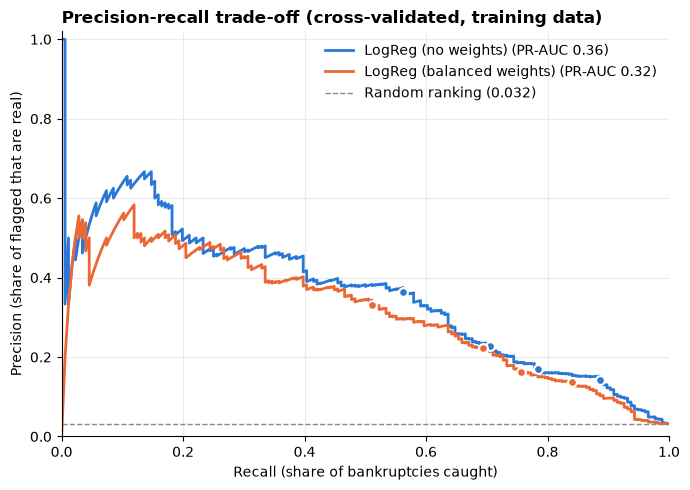

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

colors = {"LogReg (no weights)": "#2a78d6", "LogReg (balanced weights)": "#eb6834"}

fig, ax = plt.subplots(figsize=(7, 5))
for name in models:
    precision, recall, _ = precision_recall_curve(y_train, risk_scores[name])
    ap = average_precision_score(y_train, risk_scores[name])
    ax.plot(recall, precision, color=colors[name], linewidth=2, label=f"{name} (PR-AUC {ap:.2f})")
    ct = capacity_table(risk_scores[name], y_train)
    ax.scatter(ct["recall"], ct["precision"], color=colors[name], s=40, zorder=3,
               edgecolor="white", linewidth=1.5)   # dots = 5%, 10%, 15%, 20% capacity

ax.axhline(y_train.mean(), color="#888", linestyle="--", linewidth=1,
           label=f"Random ranking ({y_train.mean():.3f})")
ax.set_xlabel("Recall (share of bankruptcies caught)")
ax.set_ylabel("Precision (share of flagged that are real)")
ax.set_title("Precision-recall trade-off (cross-validated, training data)", loc="left", fontweight="bold")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()